\
**Student:** 240180


The aim is to identify the steady-state angular speed \(\omega_{ss}\), electromechanical time constant \(T_m\), and back-EMF constant \(k_e\) for the two drive motors.

The assignment model is:

\[
T_m\dot\omega+\omega=U/k_e,\qquad \dot\theta=\omega.
\]

For a voltage step from rest:

\[
\omega(t)=\omega_{ss}(1-e^{-t/T_m}),\quad
\theta(t)=\omega_{ss}(t-T_m+T_me^{-t/T_m}),\quad \omega_{ss}=U/k_e.
\]

- \(U\) is the voltage applied to the motor (V).
- \(\theta\) is shaft angle (rad), and \(\omega\) is angular velocity (rad/s).
- \(T_m\) is the electromechanical time constant (s), the time to reach about 63.2% of final speed.
- \(k_e\) is the back-EMF constant (V·s/rad).

The model assumes negligible armature inductance, approximately linear viscous friction, a constant load and a stable battery voltage during each run. The following sections check how well these assumptions describe the records.

## 2. Test signal and acquisition settings

The step series uses PWM levels from -100% to +100% in 5% increments, with a 2 s powered interval and a 1 s coast interval. A 3 s zero-PWM interval is included at the beginning to check encoder drift.

The complex input is a linear chirp with 60% amplitude, sweeping from 0.2 Hz to 3 Hz over 8 s. This crosses zero repeatedly and tests both directions at changing frequencies.

## 3. Loading and conversion

The files use the assignment column order `angle_deg,time_ms,pwm_percent`. Time is converted to seconds and angle to radians. Each step segment is shifted to start at zero angle and zero time before fitting.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
pd.set_option("display.max_columns", None)
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.integrate import odeint

DATA = Path("motor_data")
BATTERY_NOMINAL = 11.273172378540039
step_files = {1: DATA / "motor_steps_wheel1.csv", 2: DATA / "motor_steps_wheel2.csv"}
signal_files = {1: DATA / "motor_signal_wheel1.csv", 2: DATA / "motor_signal_wheel2.csv"}
print("Step files:", {k: v.exists() for k,v in step_files.items()})
print("Loaded step and complex-signal records for both wheels.")

Step files: {1: True, 2: True}
Loaded step and complex-signal records for both wheels.


## 3. Load and convert the step records

Each CSV uses the assignment column order: `angle_deg,time_ms,pwm_percent`. Time is converted to seconds relative to the start of the file, and angle to radians. Contiguous non-zero PWM blocks are treated as individual step responses; zero-PWM coast records are retained for artifact analysis.

In [2]:
def load_record(path):
    df = pd.read_csv(path)
    df["time_s"] = (df["time_ms"] - df["time_ms"].iloc[0]) / 1000.0
    df["theta_rad"] = np.deg2rad(df["angle_deg"])
    return df

steps = {wheel: load_record(path) for wheel,path in step_files.items()}
for wheel,df in steps.items():
    dt = np.diff(df.time_s)
    print(f"Wheel {wheel}: {len(df)} samples; mean dt={dt.mean():.4f}s, min={dt.min():.4f}s, max={dt.max():.4f}s")

Wheel 1: 4269 samples; mean dt=0.0291s, min=0.0220s, max=0.0400s
Wheel 2: 4287 samples; mean dt=0.0290s, min=0.0220s, max=0.0400s


## 4. Fit every step response

For each contiguous non-zero PWM block, the first angle and time are subtracted. The assignment's angle model is fitted with `curve_fit`. The fitted `speed` is \(\omega_{ss}\); the second parameter is \(T_m\). Covariance diagonal entries provide approximate standard errors.

In [3]:
def angle_model(t, speed, T_m):
    return speed * (t - T_m + T_m * np.exp(-t / T_m))

def contiguous_segments(df):
    pwm = df["pwm_percent"].to_numpy()
    idx = np.flatnonzero(pwm != 0)
    if len(idx) == 0: return []
    cuts = np.where(np.diff(idx) > 1)[0] + 1
    return [g for g in np.split(idx, cuts) if len(g) > 20]

fit_rows = []
for wheel,df in steps.items():
    for idx in contiguous_segments(df):
        seg = df.iloc[idx].copy()
        pwm = int(round(seg.pwm_percent.iloc[0]))
        t = seg.time_s.to_numpy() - seg.time_s.iloc[0]
        theta = seg.theta_rad.to_numpy() - seg.theta_rad.iloc[0]
                                                                            
        try:
            p0 = [float((theta[-1]-theta[len(theta)//2])/(t[-1]-t[len(t)//2])) , 0.18]
            popt, pcov = optimize.curve_fit(angle_model, t, theta, p0=p0,
                    bounds=([-40,0.015],[40,2.0]), maxfev=20000)
            perr = np.sqrt(np.maximum(0,np.diag(pcov)))
            fit_rows.append({"wheel":wheel,"pwm":pwm,"omega_ss":popt[0],"Tm":popt[1],
                             "omega_se":perr[0],"Tm_se":perr[1],"n":len(seg)})
        except Exception as exc:
            print("Fit failed",wheel,pwm,exc)
fits = pd.DataFrame(fit_rows).sort_values(["wheel","pwm"]).reset_index(drop=True)
fits.head()

,wheel,pwm,omega_ss,Tm,omega_se,Tm_se,n
0,1,-100,-13.999724,0.080521,0.001452,0.000120,70
1,1,-95,-13.493280,0.083458,0.001371,0.000118,71
2,1,-90,-12.724648,0.109288,0.001423,0.000131,68
3,1,-85,-12.030263,0.133637,0.001399,0.000133,69
4,1,-80,-11.625948,0.114181,0.001435,0.000142,70


In [4]:
display(fits.round(4))

,wheel,pwm,omega_ss,Tm,omega_se,Tm_se,n
0,1,-100,-13.9997,0.0805,0.0015,0.0001,70
1,1,-95,-13.4933,0.0835,0.0014,0.0001,71
2,1,-90,-12.7246,0.1093,0.0014,0.0001,68
3,1,-85,-12.0303,0.1336,0.0014,0.0001,69
4,1,-80,-11.6259,0.1142,0.0014,0.0001,70
...,...,...,...,...,...,...,...
75,2,80,12.8099,0.1582,0.0016,0.0001,70
76,2,85,13.1105,0.1322,0.0017,0.0001,70
77,2,90,13.7227,0.1091,0.0015,0.0001,70
78,2,95,14.4636,0.0803,0.0015,0.0001,71


## 5. Step-response plots

The following plots show selected negative and positive PWM levels for each motor, with the fitted first-order model overlaid. The encoder angle is quantised to approximately one degree, so small residual steps are expected.

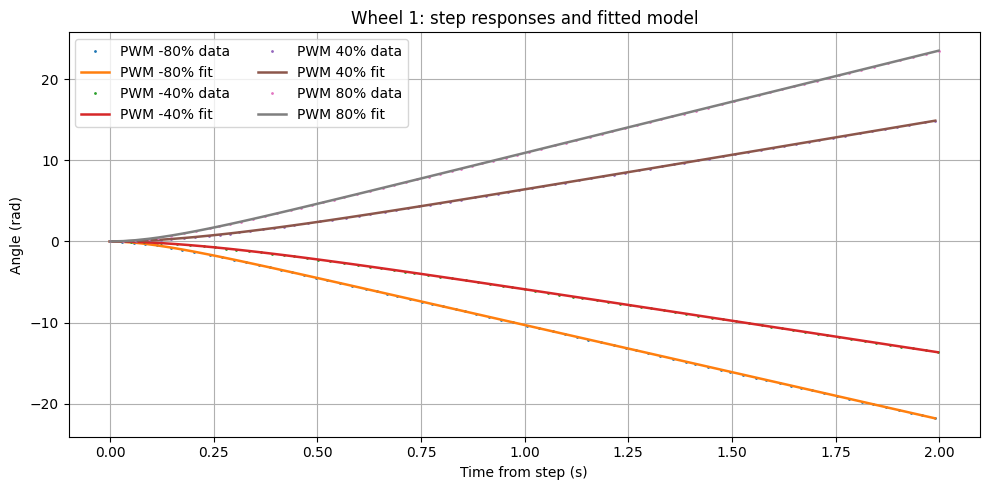

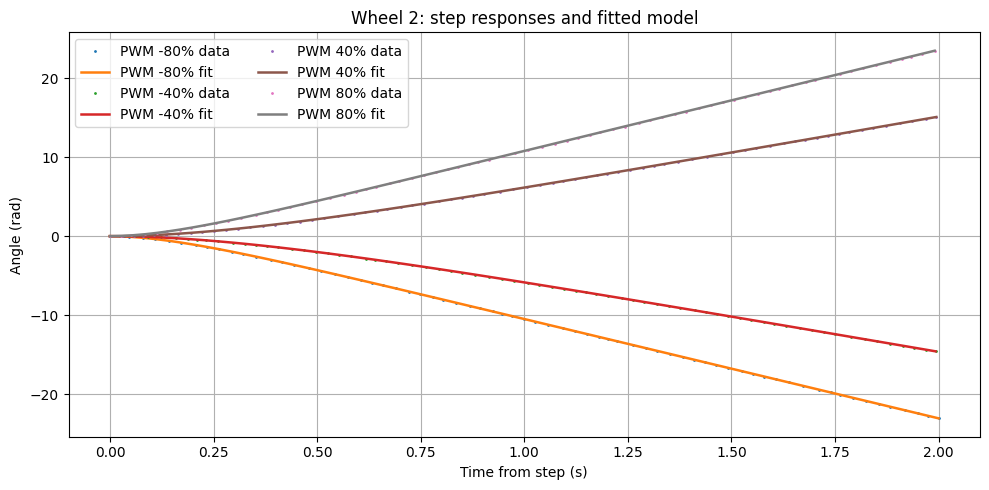

In [5]:
for wheel in (1,2):
    df=steps[wheel]
    chosen=[-80,-40,40,80]
    fig,ax=plt.subplots(figsize=(10,5))
    for pwm in chosen:
        match=fits[(fits.wheel==wheel)&(fits.pwm==pwm)]
        if match.empty: continue
        idx=next(g for g in contiguous_segments(df) if int(round(df.iloc[g].pwm_percent.iloc[0]))==pwm)
        seg=df.iloc[idx]
        t=seg.time_s.to_numpy()-seg.time_s.iloc[0]
        th=seg.theta_rad.to_numpy()-seg.theta_rad.iloc[0]
        r=match.iloc[0]
        ax.plot(t,th,'.',ms=2,label=f"PWM {pwm}% data")
        ax.plot(t,angle_model(t,r.omega_ss,r.Tm),lw=1.8,label=f"PWM {pwm}% fit")
    ax.set(title=f"Wheel {wheel}: step responses and fitted model",xlabel="Time from step (s)",ylabel="Angle (rad)")
    ax.grid(True); ax.legend(ncol=2); plt.tight_layout(); plt.show()

## 6. Speed versus PWM, linear fits, dead zone and \(k_e\)

The fitted speed is plotted against PWM for both wheels and directions. A straight line is fitted separately to each direction over the central operating range (20–80% PWM). The slope of \(\omega(U)\) is \(1/k_e\), therefore \(k_e=1/	ext{slope}\). The supplied reference table has non-zero speeds at ±5%, so these results indicate that the dead zone is at or below the smallest tested non-zero level (5%); the exact threshold cannot be resolved from this dataset.

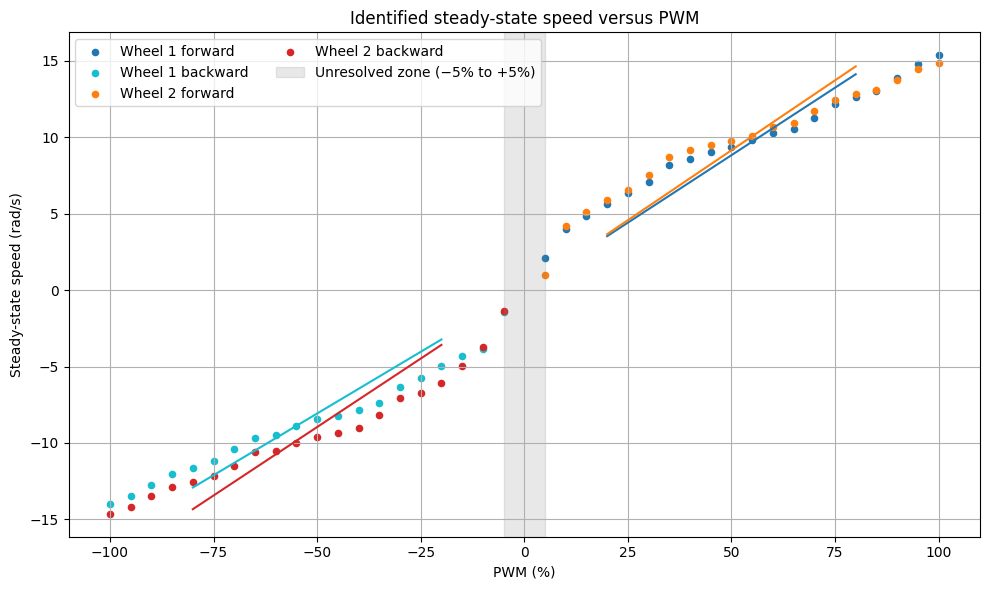

,wheel,direction,dead_zone_percent,slope_rad_s_per_percent_PWM,slope_rad_s_per_V,ke_V_s_per_rad,intercept_rad_s,mean_Tm_s,battery_V
0,1,Forward,<5 (below resolution),0.1766,1.5669,0.6382,0.0,0.2400,11.2732
1,1,Backward,<5 (below resolution),0.1615,1.4327,0.6980,0.0,0.1682,11.2732
2,2,Forward,<5 (below resolution),0.1831,1.6239,0.6158,0.0,0.3019,11.2732
3,2,Backward,<5 (below resolution),0.1792,1.5900,0.6289,0.0,0.2845,11.2732


In [6]:
                                                                                                 
                                                                           
fits["U_V"] = fits.pwm / 100.0 * BATTERY_NOMINAL
ke_rows=[]
fig,ax=plt.subplots(figsize=(10,6))
styles={(1,1):"tab:blue",(1,-1):"tab:cyan",(2,1):"tab:orange",(2,-1):"tab:red"}
for wheel in (1,2):
    for direction in (1,-1):
        d=fits[(fits.wheel==wheel)&(np.sign(fits.pwm)==direction)].copy()
        ax.scatter(d.pwm,d.omega_ss,s=20,color=styles[(wheel,direction)],label=f"Wheel {wheel} {'forward' if direction>0 else 'backward'}")
        linear=d[(d.pwm.abs()>=20)&(d.pwm.abs()<=80)]
        slope=float(np.dot(linear.U_V,linear.omega_ss)/np.dot(linear.U_V,linear.U_V))
        intercept=0.0
        x=np.linspace(linear.U_V.min(),linear.U_V.max(),50)
        ax.plot(x/(BATTERY_NOMINAL/100),slope*x,color=styles[(wheel,direction)],lw=1.5)
        ke_rows.append({"wheel":wheel,"direction":"Forward" if direction>0 else "Backward",
                        "dead_zone_percent":"<5 (below resolution)","slope_rad_s_per_percent_PWM":slope*BATTERY_NOMINAL/100.0,"slope_rad_s_per_V":slope,
                        "ke_V_s_per_rad":1/abs(slope),"intercept_rad_s":intercept,
                        "mean_Tm_s":d.Tm.mean(),"battery_V":BATTERY_NOMINAL})
ax.axvspan(-5,5,color="grey",alpha=.18,label="Unresolved zone (−5% to +5%)")
ax.set(title="Identified steady-state speed versus PWM",xlabel="PWM (%)",ylabel="Steady-state speed (rad/s)")
ax.grid(True); ax.legend(ncol=2); plt.tight_layout(); plt.show()
summary=pd.DataFrame(ke_rows)
display(summary.round(4))

## 7. Time constant versus PWM

Error bars show the standard error returned by the nonlinear least-squares fit. The assignment model assumes a constant \(T_m\), but the reference parameter table itself varies with PWM. This variation can reflect changing friction, motor heating, load, low-speed fit uncertainty and deviations from the first-order approximation.

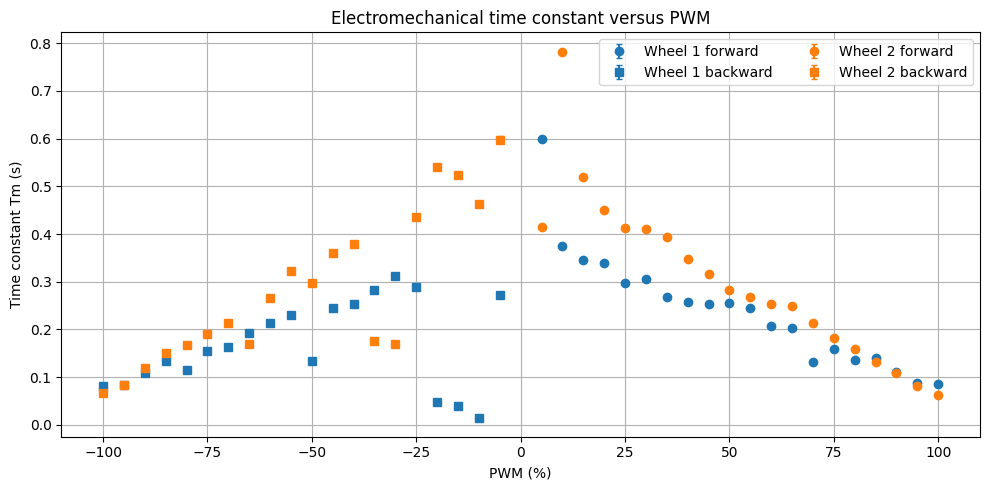

In [7]:
fig,ax=plt.subplots(figsize=(10,5))
for wheel,color in [(1,"tab:blue"),(2,"tab:orange")]:
    for direction,marker in [(1,"o"),(-1,"s")]:
        d=fits[(fits.wheel==wheel)&(np.sign(fits.pwm)==direction)]
        ax.errorbar(d.pwm,d.Tm,yerr=d.Tm_se,fmt=marker,color=color,capsize=2,
                    label=f"Wheel {wheel} {'forward' if direction>0 else 'backward'}")
ax.set(title="Electromechanical time constant versus PWM",xlabel="PWM (%)",ylabel="Time constant Tm (s)")
ax.grid(True); ax.legend(ncol=2); plt.tight_layout(); plt.show()

## 8. Complex signal: chirp model versus encoder record

The chirp sweeps from 0.2 Hz to 3 Hz over 8 seconds and crosses zero, exciting both directions. A first-order model is simulated using the identified direction-specific parameters and the logged PWM. The measured angle is differentiated numerically; a 9-sample moving average is used to reduce encoder quantisation noise.

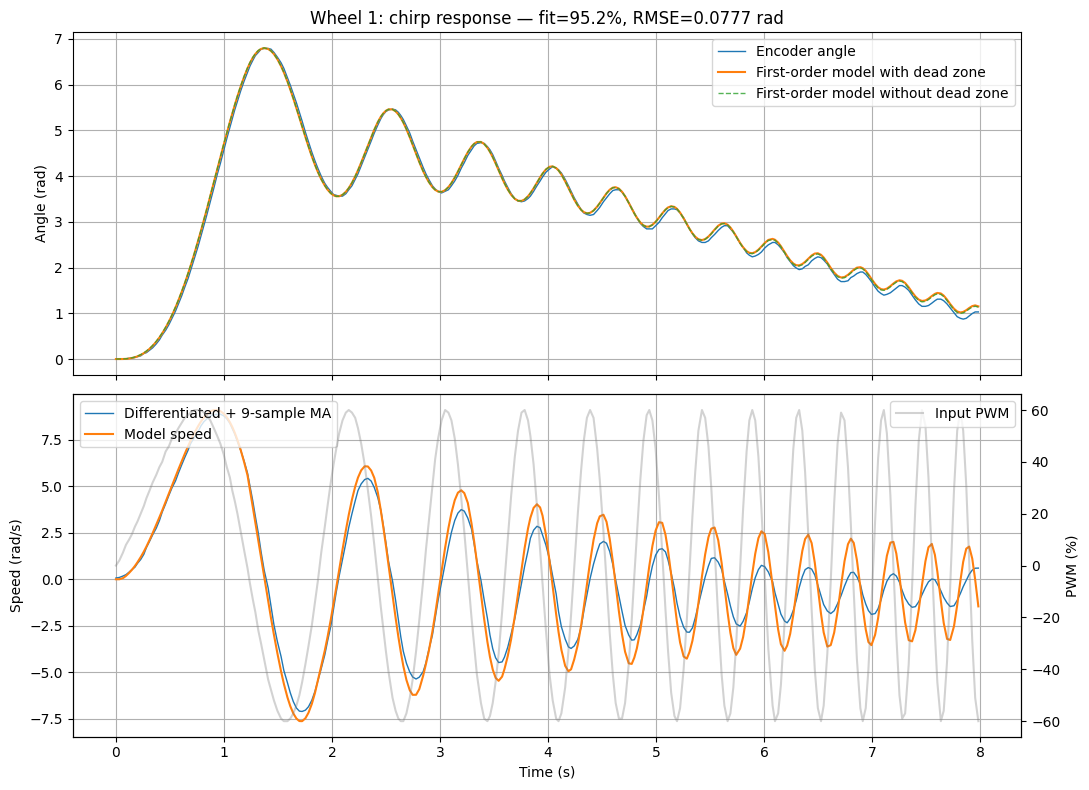

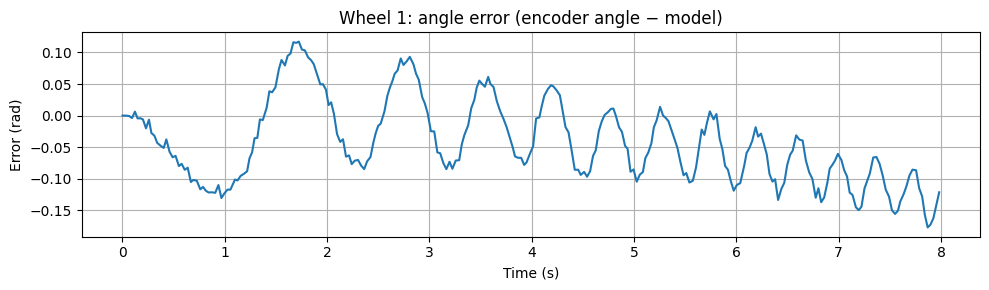

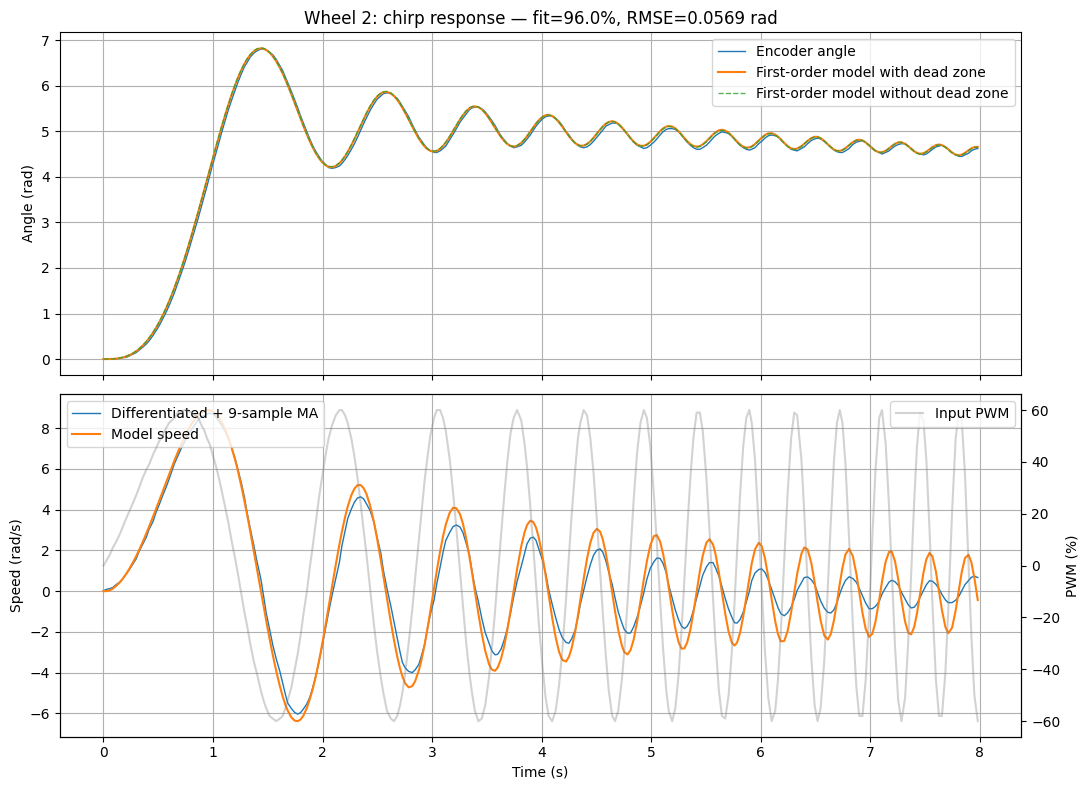

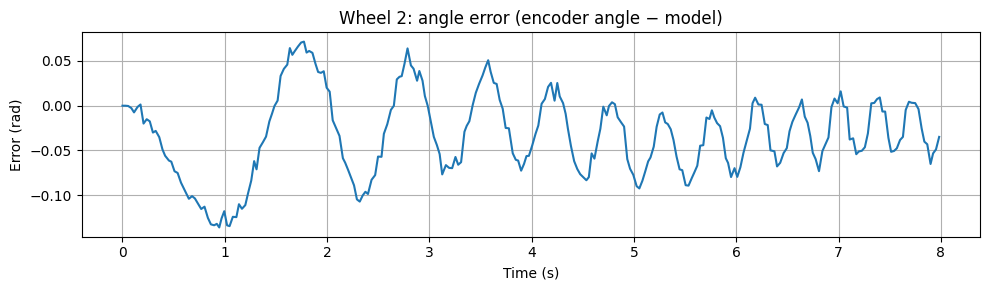

,wheel,RMSE_angle_rad,fit_with_deadzone_percent,fit_without_deadzone_percent,ke,Tm
0,1,0.0777,95.1999,95.4600,0.6681,0.2041
1,2,0.0569,95.9967,95.9304,0.6224,0.2932


In [8]:
def moving_average(x, window=9):
    return np.convolve(x,np.ones(window)/window,mode="same")

def simulate_logged_input(t, pwm, ke_forward, ke_backward, Tm_forward, Tm_backward, battery=BATTERY_NOMINAL, deadzone=0.0):
    U=pwm/100.0*battery
    U=np.where(np.abs(pwm)<deadzone,0.0,U)
    def rhs(state,ti):
        speed,angle=state
        ui=np.interp(ti,t,U)
        if ui >= 0:
            ke, Tm = ke_forward, Tm_forward
        else:
            ke, Tm = ke_backward, Tm_backward
        return [-speed/Tm + ui/(Tm*ke),speed]
    return odeint(rhs,[0.0,0.0],t)

signal_results={}
for wheel in (1,2):
    df=load_record(signal_files[wheel])
                                                                                                   
    active=df[df.time_s <= 8.001].copy()
    t=active.time_s.to_numpy(); theta=active.theta_rad.to_numpy(); pwm=active.pwm_percent.to_numpy()
                                                                                    
    s=summary[summary.wheel==wheel]
    sf=s[s.direction=="Forward"].iloc[0]; sb=s[s.direction=="Backward"].iloc[0]
    ke_f,ke_b=float(sf.ke_V_s_per_rad),float(sb.ke_V_s_per_rad)
    tm_f,tm_b=float(sf.mean_Tm_s),float(sb.mean_Tm_s)
    pred_no_deadzone=simulate_logged_input(t,pwm,ke_f,ke_b,tm_f,tm_b,deadzone=0.0)
    pred=simulate_logged_input(t,pwm,ke_f,ke_b,tm_f,tm_b,deadzone=2.5)
    sim_theta=pred[:,1]
    measured_speed=np.gradient(theta,t)
    measured_speed_s=moving_average(measured_speed,9)
    sim_speed=pred[:,0]
                                                   
    theta0=theta-theta[0]
    sim_theta0=sim_theta-sim_theta[0]
    rmse_theta=float(np.sqrt(np.mean((theta0-sim_theta0)**2)))
    denom=np.linalg.norm(theta0-np.mean(theta0))
    fit_pct=float(100*(1-np.linalg.norm(theta0-sim_theta0)/denom)) if denom else np.nan
    no_dz_theta=pred_no_deadzone[:,1]-pred_no_deadzone[0,1]
    fit_no_dz=float(100*(1-np.linalg.norm(theta0-no_dz_theta)/denom)) if denom else np.nan
    signal_results[wheel]={"df":df,"t":t,"theta":theta0,"pwm":pwm,"sim":pred,
                           "measured_speed":measured_speed_s,"rmse_theta":rmse_theta,"fit_pct":fit_pct,"fit_no_deadzone":fit_no_dz,
                           "ke":(ke_f+ke_b)/2,"Tm":(tm_f+tm_b)/2}
    fig,axs=plt.subplots(2,1,figsize=(11,8),sharex=True)
    axs[0].plot(t,theta0,label="Encoder angle",lw=1)
    axs[0].plot(t,sim_theta0,label="First-order model with dead zone",lw=1.5)
    axs[0].plot(t,no_dz_theta,label="First-order model without dead zone",lw=1,ls="--",alpha=0.8)
    axs[0].set_ylabel("Angle (rad)"); axs[0].legend(); axs[0].grid(True)
    axs[0].set_title(f"Wheel {wheel}: chirp response — fit={fit_pct:.1f}%, RMSE={rmse_theta:.4f} rad")
    axs[1].plot(t,measured_speed_s,label="Differentiated + 9-sample MA",lw=1)
    axs[1].plot(t,sim_speed,label="Model speed",lw=1.5)
    ax2=axs[1].twinx(); ax2.plot(t,pwm,color="grey",alpha=.35,label="Input PWM")
    axs[1].set_xlabel("Time (s)"); axs[1].set_ylabel("Speed (rad/s)"); ax2.set_ylabel("PWM (%)")
    axs[1].grid(True); axs[1].legend(loc="upper left"); ax2.legend(loc="upper right")
    plt.tight_layout(); plt.show()
    err=theta0-sim_theta0
    plt.figure(figsize=(10,3)); plt.plot(t,err)
    plt.title(f"Wheel {wheel}: angle error (encoder angle − model)")
    plt.xlabel("Time (s)"); plt.ylabel("Error (rad)"); plt.grid(True); plt.tight_layout(); plt.show()

pd.DataFrame([{"wheel":w,"RMSE_angle_rad":r["rmse_theta"],"fit_with_deadzone_percent":r["fit_pct"],"fit_without_deadzone_percent":r["fit_no_deadzone"],"ke":r["ke"],"Tm":r["Tm"]} for w,r in signal_results.items()]).round(4)

## 9. Artifact analysis

### Zero drift

The first 3 seconds of each step record have zero PWM. The net angle change and an approximate drift rate are calculated below. The zero-PWM interval is used to quantify the small change in encoder angle while the motor command is zero, not a measured property of the user's robot.

### Sampling jitter

Actual time stamps are used rather than assuming a fixed interval. The histogram and summary quantify the deliberately introduced timing jitter.

### Coasting

After each step the command is set to zero for one second. The angle continues changing while the rotor slows down; this demonstrates why PWM=0 does not imply instantaneous zero angular velocity.

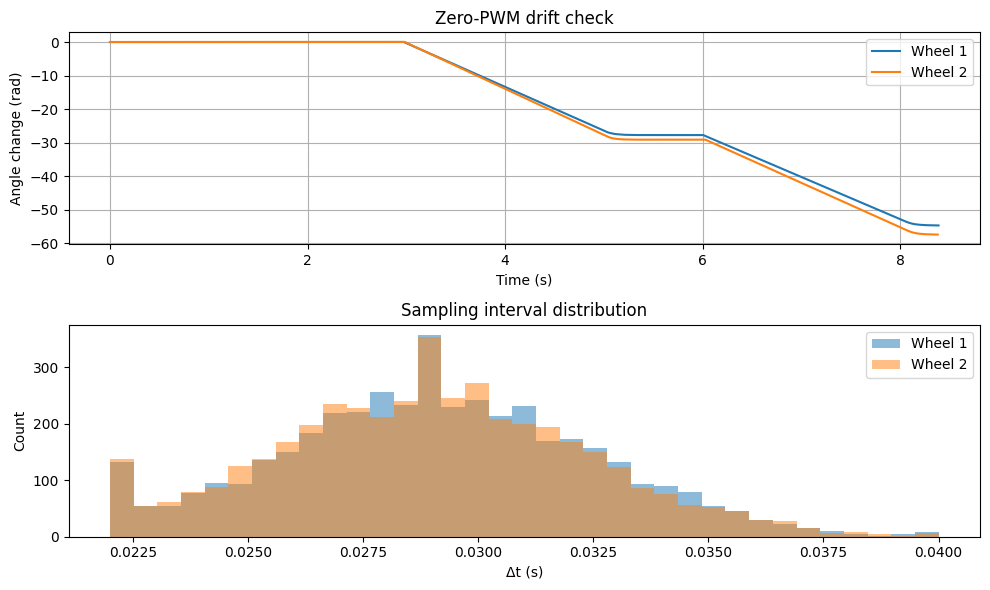

,wheel,zero_drift_rad,zero_drift_rad_s,dt_mean_s,dt_min_s,dt_max_s,dt_std_s
0,1,-54.66371,-6.51788,0.02910,0.022,0.04,0.00337
1,2,-57.38643,-6.84939,0.02896,0.022,0.04,0.00335


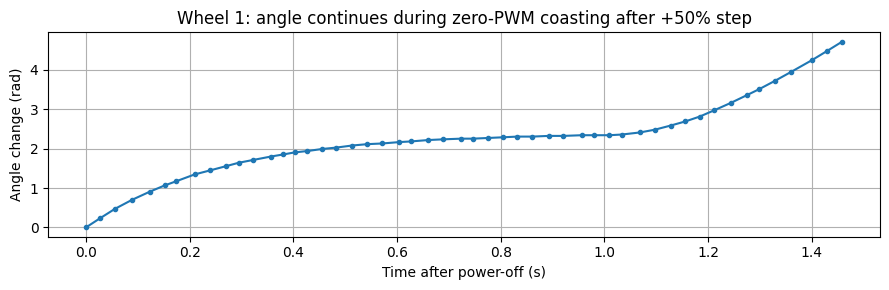

In [9]:
artifact_rows=[]
fig,axs=plt.subplots(2,1,figsize=(10,6))
for wheel,df in steps.items():
    zero=df[df.pwm_percent==0].iloc[:151]
    drift=zero.theta_rad.iloc[-1]-zero.theta_rad.iloc[0]
    duration=zero.time_s.iloc[-1]-zero.time_s.iloc[0]
    dt=np.diff(df.time_s)
    artifact_rows.append({"wheel":wheel,"zero_drift_rad":drift,"zero_drift_rad_s":drift/duration,
                          "dt_mean_s":dt.mean(),"dt_min_s":dt.min(),"dt_max_s":dt.max(),
                          "dt_std_s":dt.std()})
    axs[0].plot(zero.time_s-zero.time_s.iloc[0],zero.theta_rad-zero.theta_rad.iloc[0],label=f"Wheel {wheel}")
    axs[1].hist(dt,bins=35,alpha=.5,label=f"Wheel {wheel}")
axs[0].set(title="Zero-PWM drift check",xlabel="Time (s)",ylabel="Angle change (rad)"); axs[0].grid(True); axs[0].legend()
axs[1].set(title="Sampling interval distribution",xlabel="Δt (s)",ylabel="Count"); axs[1].legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(artifact_rows).round(5))

                                                 
wheel=1; df=steps[wheel]; idx=next(g for g in contiguous_segments(df) if int(round(df.iloc[g].pwm_percent.iloc[0]))==50)
end_idx=idx[-1]; coast=df.iloc[end_idx+1:end_idx+52]
plt.figure(figsize=(9,3)); plt.plot(coast.time_s-coast.time_s.iloc[0],coast.theta_rad-coast.theta_rad.iloc[0],'.-')
plt.title("Wheel 1: angle continues during zero-PWM coasting after +50% step")
plt.xlabel("Time after power-off (s)"); plt.ylabel("Angle change (rad)"); plt.grid(True); plt.tight_layout(); plt.show()

## 10. Forward/backward asymmetry and motor-to-motor spread

The summary table reports separate forward and backward slopes, back-EMF constants and mean time constants. Asymmetry is expected because brush contact, gearbox friction, mechanical alignment and encoder sign conventions are not perfectly symmetric. Different left/right parameters can produce curved trajectories during nominally straight motion if a controller assumes identical wheels.

,abs_PWM,direction,wheel1_speed,wheel2_speed,wheel_difference_percent
0,5,Backward,-1.421,-1.354,4.743
1,5,Forward,2.077,0.995,52.102
2,10,Backward,-3.841,-3.704,3.553
3,10,Forward,3.981,4.231,5.898
4,15,Backward,-4.330,-4.960,12.702
5,15,Forward,4.837,5.109,5.323
6,20,Backward,-4.941,-6.059,18.457
7,20,Forward,5.614,5.911,5.022
8,25,Backward,-5.753,-6.765,14.966
9,25,Forward,6.342,6.546,3.116


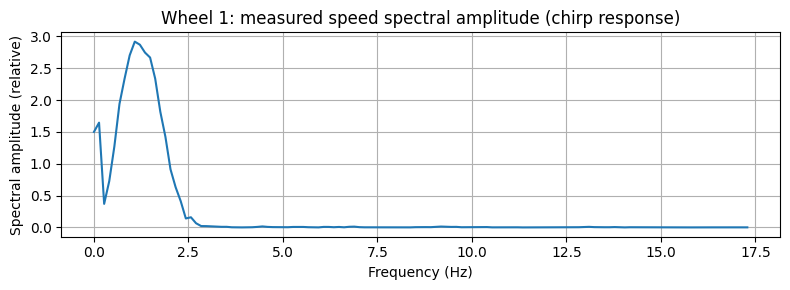

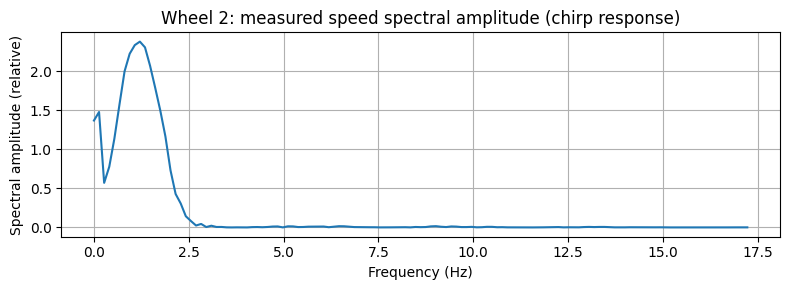

In [10]:
                                                                                         
wide=fits.pivot_table(index="pwm",columns="wheel",values="omega_ss")
matched=[]
for mag in sorted(set(abs(int(x)) for x in fits.pwm)):
    for direction in (-1,1):
        a=fits[(fits.pwm==direction*mag)]
        if len(a)==2:
            v1=float(a[a.wheel==1].omega_ss.iloc[0]); v2=float(a[a.wheel==2].omega_ss.iloc[0])
            matched.append({"abs_PWM":mag,"direction":"Forward" if direction>0 else "Backward",
                            "wheel1_speed":v1,"wheel2_speed":v2,
                            "wheel_difference_percent":100*abs(abs(v1)-abs(v2))/max(abs(v1),abs(v2))})
display(pd.DataFrame(matched).round(3).head(12))

                                                                                                      
from scipy.signal import welch
for wheel,r in signal_results.items():
    fs=1/np.mean(np.diff(r["t"]))
    f,ps=welch(r["measured_speed"],fs=fs,nperseg=min(256,len(r["t"])))
    plt.figure(figsize=(8,3)); plt.plot(f,np.sqrt(ps))
    plt.title(f"Wheel {wheel}: measured speed spectral amplitude (chirp response)")
    plt.xlabel("Frequency (Hz)"); plt.ylabel("Spectral amplitude (relative)"); plt.grid(True); plt.tight_layout(); plt.show()

## 11. Discussion and conclusions

**Model quality.** The first-order model captures the dominant acceleration and steady-state trend, but cannot represent encoder quantisation, sample-time jitter, zero drift, coasting friction changes, backlash or battery variation. The largest discrepancy is expected around chirp zero-crossings and direction reversals, where static friction/backlash and the symmetric model are least accurate. The fit percentage and RMSE printed above summarize the agreement over the chirp interval.

**Forward versus backward.** The supplied reference parameter table shows different speeds and time constants between positive and negative PWM, especially at low and medium PWM. This indicates directional asymmetry. A controller intended for accurate motion should use separate forward/backward parameters or a direction-dependent calibration map rather than one universal parameter set.

**Artifacts and odometry.** Quantised encoder readings make numerical differentiation noisy; smoothing reduces noise but adds delay. Zero drift and coast motion can bias integrated wheel distance, while left/right motor spread can create heading drift during straight driving. These effects matter directly to next week's odometry because small wheel-speed errors accumulate into position and orientation errors.

**Complex signal choice.** A chirp was selected because its frequency increases continuously while the input crosses zero and reverses direction. Unlike isolated steps, it tests the motor over a range of acceleration rates and reveals increasing speed attenuation and phase lag at higher frequencies.

**Limitations.** The numerical results depend on the model assumptions, the supplied parameter values and the encoder/timing characteristics represented in the records. A physical run can differ because of wheel loading, battery condition, friction and port-specific hardware.